In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье

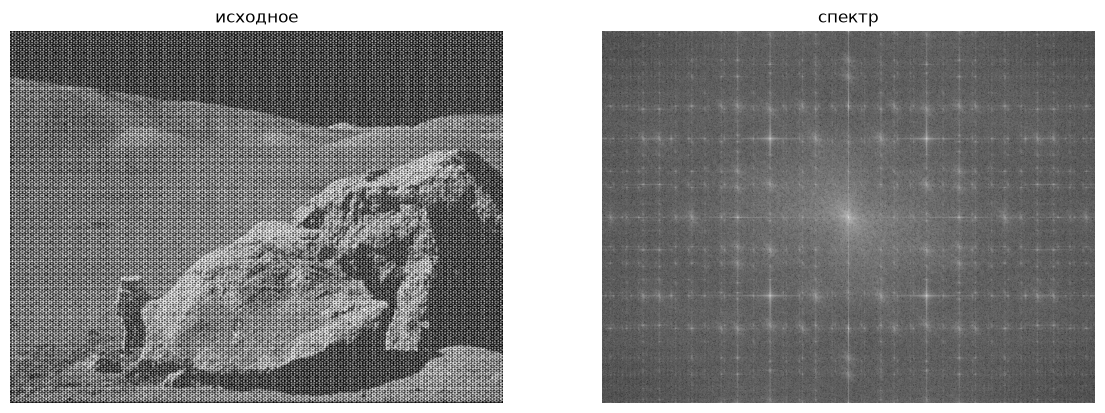

In [3]:
img = cv2.imread('periodic_noise.JPG', cv2.IMREAD_GRAYSCALE).astype(np.float32)
h, w = img.shape
cy, cx = h // 2, w // 2

F = np.fft.fftshift(np.fft.fft2(img))
spectrum = np.log(1 + np.abs(F))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(img, cmap="gray")
ax[0].set_title('исходное')
ax[1].imshow(spectrum, cmap="gray")
ax[1].set_title('спектр')
for a in ax:
    a.axis('off')
plt.show()

## Задание 1. ВЧ фильтр Гаусса

H(u, v) = 1 - exp(-D(u, v)^2 / (2 * D0^2)), где D это расстояние от центра спектра.

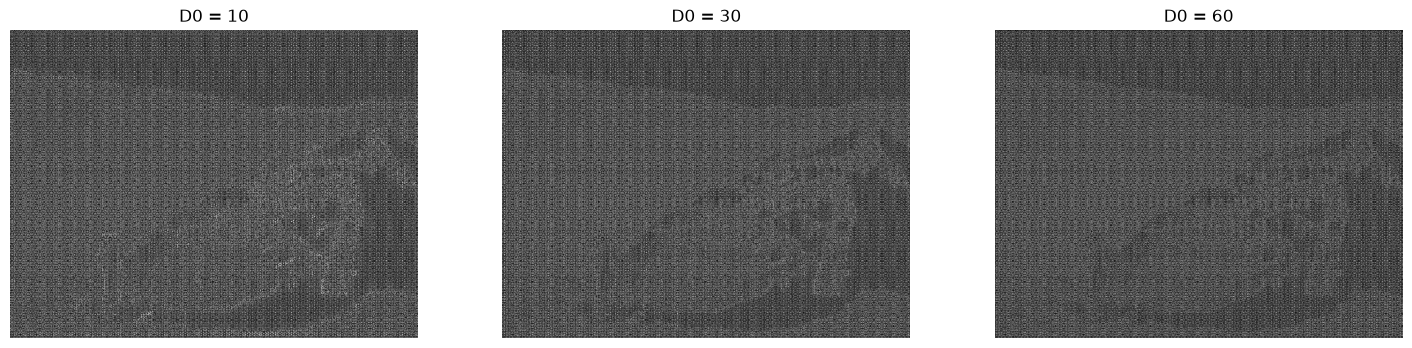

In [4]:
y, x = np.mgrid[0:h, 0:w]
D = np.sqrt((x - cx) ** 2 + (y - cy) ** 2)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for i, D0 in enumerate([10, 30, 60]):
    H = 1 - np.exp(-D ** 2 / (2 * D0 ** 2))
    out = np.real(np.fft.ifft2(np.fft.ifftshift(F * H)))
    ax[i].imshow(np.abs(out), cmap="gray")
    ax[i].set_title('D0 = %d' % D0)
    ax[i].axis('off')
plt.show()

ВЧ фильтр убирает плавные изменения яркости и оставляет границы. Чем больше D0, тем больше низких частот вырезается. На этом изображении после фильтра хорошо видна сетка периодического шума, так как он высокочастотный.

## Задание 2. Свертка через Фурье

По теореме о свертке f * g = IFFT(FFT(f) * FFT(g)). Ядро дополняется нулями до размера изображения и сдвигается так, чтобы его центр был в точке (0, 0).

In [5]:
def conv_fft(img, kernel):
    kh, kw = kernel.shape
    k = np.zeros(img.shape, np.float32)
    k[:kh, :kw] = kernel
    k = np.roll(k, (-(kh // 2), -(kw // 2)), axis=(0, 1))
    return np.real(np.fft.ifft2(np.fft.fft2(img) * np.fft.fft2(k)))

макс. разница с filter2D: 0.0001373291


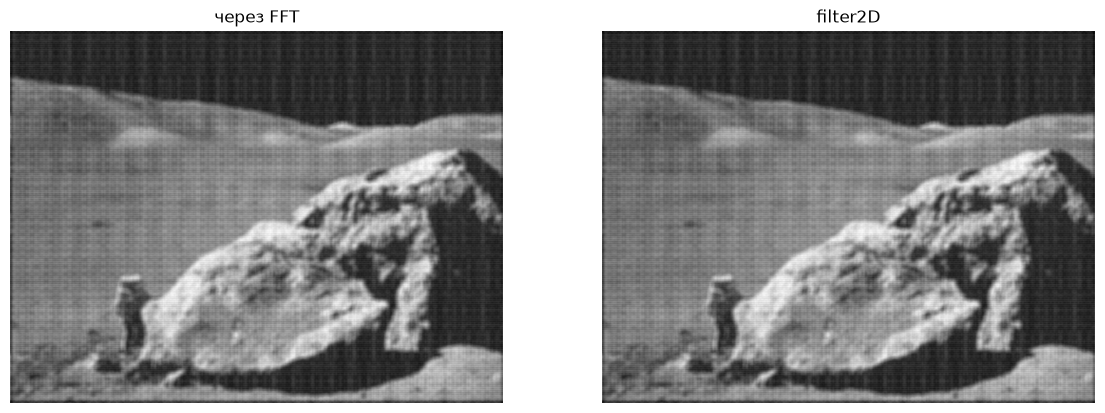

In [6]:
kernel = np.ones((9, 9), np.float32) / 81

res_fft = conv_fft(img, kernel)
# через Фурье свертка получается циклической, поэтому для сравнения
# дополняю изображение периодически (BORDER_WRAP в filter2D не поддерживается)
p = 4
img_wrap = np.pad(img, p, mode='wrap')
res_cv = cv2.filter2D(img_wrap, -1, kernel)[p:-p, p:-p]

print('макс. разница с filter2D:', np.abs(res_fft - res_cv).max())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(res_fft, cmap="gray")
ax[0].set_title('через FFT')
ax[1].imshow(res_cv, cmap="gray")
ax[1].set_title('filter2D')
for a in ax:
    a.axis('off')
plt.show()

Результаты совпадают с точностью до ошибок округления float32.

## Задание 3. Удаление периодического шума

На спектре шум виден как набор ярких точек вне центра. Нахожу их как точки, где спектр сильно выше своего сглаженного значения, и зануляю кружками вокруг них (режекторный фильтр). Центр не трогаю, там основная информация изображения.

In [7]:
diff = spectrum - cv2.blur(spectrum, (15, 15))
peaks = np.argwhere((diff > 2) & (D > 15))
print('найдено точек:', len(peaks))

mask = np.ones(img.shape, np.float32)
for py, px in peaks:
    cv2.circle(mask, (int(px), int(py)), 6, 0, -1)

img_clean = np.real(np.fft.ifft2(np.fft.ifftshift(F * mask)))
img_clean = np.clip(img_clean, 0, 255).astype(np.uint8)

найдено точек: 2075


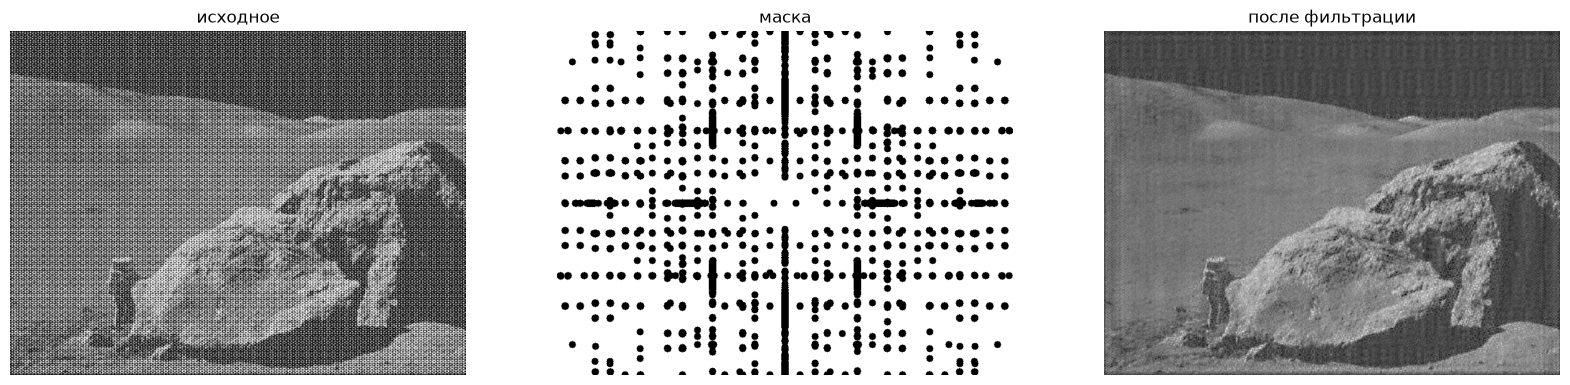

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
ax[0].imshow(img, cmap="gray")
ax[0].set_title('исходное')
ax[1].imshow(mask, cmap="gray")
ax[1].set_title('маска')
ax[2].imshow(img_clean, cmap="gray")
ax[2].set_title('после фильтрации')
for a in ax:
    a.axis('off')
plt.show()

## Вывод

ВЧ фильтр Гаусса выделяет границы и мелкие детали, сила фильтрации задается D0. Свертка через FFT дает тот же результат, что и filter2D, если учесть, что она циклическая. Периодический шум на спектре выглядит как отдельные яркие пики, после их зануления сетка на изображении почти полностью пропала, остались слабые следы в виде полос.